<a href="https://colab.research.google.com/github/Lourdes-Churacutipa/Repositorio-de-lourdes/blob/main/Lab9_6_Desafio_Chosica_Peru.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Desafío de Modelamiento Hidrológico: el Río Rímac en Chosica
## Ciencia de Datos Ambientales – Aplicado al Perú

**Duración:** 95 minutos (taller en equipos) · **Entorno:** Google Colab (recomendado: *GPU T4*)

Cerramos el bloque de *deep learning* con un **desafío**: cada equipo construye el mejor modelo posible para simular el caudal diario del **río Rímac en la estación Chosica** (CAMELS-PE `PE_202906`). Pueden usar **cualquiera** de las arquitecturas de los Labs 9_1 a 9_5.

Las reglas son iguales para todos los equipos: los mismos datos, los mismos periodos, la misma métrica y el mismo formato de entrega. Así, la única diferencia entre equipos es **el modelo**, y los resultados se pueden comparar en un único tablero, como en una competencia de [Kaggle](https://www.kaggle.com/competitions).

---

### Reglas del desafío

| | Regla |
|---|---|
| **Objetivo** | Simular el caudal diario observado en Chosica (`flow_obs`, en mm/día) |
| **Entrenamiento** | 1998-09-01 a 2012-08-31: con caudal observado |
| **Validación** | 2012-09-01 a 2016-08-31: con caudal observado, para elegir el modelo (**tablero público**) |
| **Prueba** | 2016-09-01 a 2023-05-31: caudal **oculto**, define el resultado final (**tablero privado**) |
| **Métrica principal** | **NSE** en el periodo de prueba (desempate: KGE) |
| **Entrega** | Un CSV con el caudal simulado para **todos** los días de 1998-09-01 a 2023-05-31 |
| **Entradas permitidas** | Todo lo que traen los archivos del desafío, **excepto** el caudal observado de Chosica |

Tres reglas de buena práctica, que en una competencia real también importan:

1. **Nada del periodo de prueba se usa para decidir**: ni para normalizar, ni para el *early stopping*, ni para elegir hiperparámetros. Las decisiones se toman con la **validación**.
2. **El caudal observado de Chosica no es una entrada.** Es un modelo de **simulación**: recibe clima y produce caudal. Por eso un pronosticador como Chronos (Lab 9_4), que necesita el caudal pasado, no aplica aquí tal cual.
3. **El tablero privado se abre una sola vez**, al final. Si miras la prueba y vuelves a ajustar, tu NSE de prueba deja de ser una estimación honesta.

### Objetivos de aprendizaje

1. Plantear un problema de modelamiento con **periodos, métrica y formato de entrega fijos** (estandarización).
2. Superar dos **líneas base**: el modelo hidrológico PISCO-ARNOVIC y una LSTM de referencia.
3. Elegir el modelo con la **validación** y no con la prueba.
4. Evaluar con varias métricas (NSE, KGE, NSE-log, PBIAS) y explicar **dónde** falla el modelo.

### Plan del taller

| Tiempo | Actividad |
|---|---|
| 0–15 min | Secciones 1–3: datos, reglas y líneas base (todos juntos) |
| 15–70 min | Sección 4: cada equipo mejora su modelo y mira solo el **tablero público** |
| 70–80 min | Sección 5: se guarda el envío y se abre el **tablero privado** |
| 80–95 min | Puesta en común: ¿qué funcionó, qué no y por qué? |

In [ ]:
# Instalar lo necesario si el entorno no lo trae (en Colab normalmente ya está todo)
import importlib.util, subprocess, sys

for paquete in ['tensorflow', 'gdown']:
    if importlib.util.find_spec(paquete) is None:
        print(f'Instalando {paquete}...')
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', paquete])

import tensorflow as tf
print(f'TensorFlow {tf.__version__} | GPU: {len(tf.config.list_physical_devices("GPU")) > 0}')

TensorFlow 2.21.0 | GPU: True


In [ ]:
import os, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

np.random.seed(42)
plt.rcParams['figure.figsize'] = (12, 4.5)
plt.rcParams['font.size'] = 11

# 1. Datos del desafío

| Archivo | Contenido |
|---|---|
| `PE_202906.csv` | **Chosica**: forzantes diarios 1981–2025 y caudal observado 1998–2023 |
| `PE_212604.csv` | **Río Blanco** (aguas arriba, 202 km²): forzantes y caudal observado |
| `PE_472E24B0.csv` | **Santa Eulalia** (aguas arriba, 1 077 km²): forzantes |
| `PE_47A03AC4.csv` | **Autisha** (dentro de Santa Eulalia, 792 km²): forzantes |
| `camels_pe_atributos.csv` | Atributos estáticos de las 136 cuencas de CAMELS-PE |

Las tres estaciones aguas arriba son **opcionales**: sirven a quien quiera probar un modelo espacial (Lab 9_5).

In [ ]:
# Archivos compartidos en Google Drive (ID o enlace completo)
import gdown                                        # gdown viene preinstalado en Google Colab

ARCHIVOS = {
    'camels_pe_atributos.csv': '1tVbnC0athzvfe_Ht1GyjfDcg-KUSrzWZ',
    'PE_202906.csv':           '1yNNrR8-b1vLbZ-XfCI-YiNJaaMdHHYZD',          # Chosica (objetivo, obligatorio)
    'PE_212604.csv':           '1L0Hzy6Pg4I19LBUXqpJkAK8azyR9HiGh',       # Río Blanco (opcional)
    'PE_472E24B0.csv':         '1Fy_a4-zIylGfJMCfSmgI-iXSzgdf5Wx8',    # Santa Eulalia (opcional)
    'PE_47A03AC4.csv':         '1Gyy4pmakSoNPuyJOsXlOIlnYOwBJlbOu',          # Autisha (opcional)
}
OBLIGATORIOS = ['camels_pe_atributos.csv', 'PE_202906.csv']

for archivo, fuente in ARCHIVOS.items():
    if os.path.exists(archivo):
        continue
    if fuente.startswith('PEGAR'):
        if archivo in OBLIGATORIOS:
            raise ValueError(f'Falta el enlace de Google Drive de {archivo}')
        print(f'(opcional) sin enlace para {archivo}: se omite')
        continue
    enlace = re.search(r'(?:id=|/d/)([\w-]{20,})', fuente)          # acepta un enlace de Drive o el ID solo
    gdown.download(id=enlace.group(1) if enlace else fuente, output=archivo, quiet=True)
print('Archivos listos:', sorted(f for f in os.listdir('.') if f.endswith('.csv')))

NameError: name 'os' is not defined

In [ ]:
OBJETIVO = 'PE_202906'
atributos = pd.read_csv('camels_pe_atributos.csv').set_index('gauge_id')
grupo = atributos[atributos['nested_group_id'] == OBJETIVO]
grupo[['gauge_name', 'area', 'elev_mean', 'downstream_gauge_id', 'gauge_record_start', 'gauge_record_end',
       'gauge_perc_obs', 'reservoir_n']].sort_values('area', ascending=False)

,gauge_name,area,elev_mean,downstream_gauge_id,gauge_record_start,gauge_record_end,gauge_perc_obs,reservoir_n
gauge_id,,,,,,,,
PE_202906,Chosica,2319.037,3922.567,NONE,1998-09-01,2023-05-31,54.91,30
PE_472E24B0,Santa Eulalia,1077.418,4018.786,PE_202906,2007-09-01,2008-08-30,2.22,24
PE_47A03AC4,Autisha,791.698,4409.050,PE_472E24B0,2024-04-01,2025-07-31,2.93,21
PE_212604,Rio Blanco,202.173,4647.439,PE_202906,1988-09-01,2025-11-10,75.49,1


## 1.1 ¿Qué tiene de especial esta cuenca?

- **Gran desnivel:** la estación está a 869 m s. n. m., pero la cuenca sube hasta 5 560 m y su altitud media es de unos 3 900 m. Casi toda la lluvia cae en la sierra.
- **Muy estacional:** llueve de diciembre a abril. El resto del año el río vive del agua almacenada (suelo, acuíferos, lagunas).
- **Cuenca regulada:** CAMELS-PE registra **30 embalses** en la cuenca. Además, el Rímac recibe agua trasvasada desde la vertiente atlántica (sistema Marca) y alimenta centrales hidroeléctricas y el agua potable de Lima. Parte del caudal de estiaje **no depende de la lluvia del día**, sino de decisiones de operación que **no están en los datos**.
- **Eventos extremos en la prueba:** el **Niño Costero de 2017** produjo huaicos e inundaciones en Chosica.

['prec', 'prec_var', 'flow_obs', 'flow_sim', 'pet', 'tmin', 'tmean', 'tmax', 'srad', 'vprp']
Caudal observado: 1998-09-01 → 2023-05-31


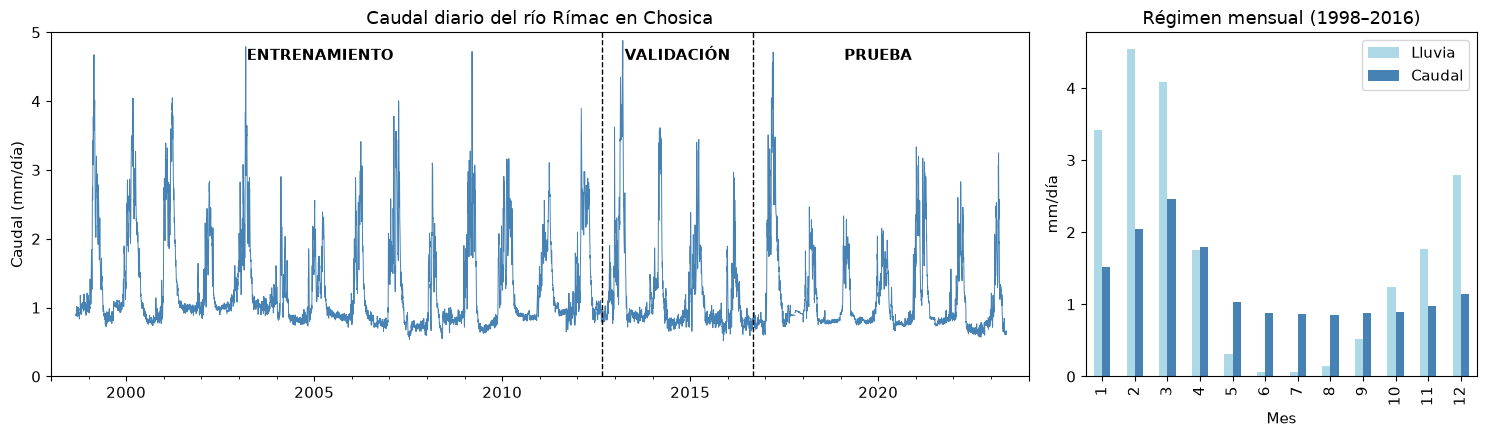

In [ ]:
d = pd.read_csv('PE_202906.csv', parse_dates=['date'], index_col='date')
print(d.columns.tolist())
print('Caudal observado:', d['flow_obs'].first_valid_index().date(), '→', d['flow_obs'].last_valid_index().date())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={'width_ratios': [2.5, 1]})
d['flow_obs'].loc['1998':'2023'].plot(ax=ax1, lw=0.7, color='steelblue', label='Observado')
for x in ['2012-09-01', '2016-09-01']:
    ax1.axvline(pd.Timestamp(x), color='k', ls='--', lw=1)
for x, texto in [('2005-03-01', 'ENTRENAMIENTO'), ('2014-09-01', 'VALIDACIÓN'), ('2020-01-01', 'PRUEBA')]:
    ax1.text(pd.Timestamp(x), 4.6, texto, ha='center', fontweight='bold')
ax1.set_ylabel('Caudal (mm/día)'); ax1.set_xlabel(''); ax1.set_ylim(0, 5)
ax1.set_title('Caudal diario del río Rímac en Chosica')

mensual = d.loc['1998-09':'2016-08'].groupby(d.loc['1998-09':'2016-08'].index.month)[['prec', 'flow_obs']].mean()
mensual.plot(kind='bar', ax=ax2, color=['lightblue', 'steelblue'])
ax2.set_xlabel('Mes'); ax2.set_ylabel('mm/día'); ax2.set_title('Régimen mensual (1998–2016)')
ax2.legend(['Lluvia', 'Caudal'])
plt.tight_layout(); plt.show()

Observa que en estiaje (junio–octubre) casi no llueve, pero el caudal **no baja de ~0.8 mm/día**. Ese caudal base es parte de lo que el modelo tiene que aprender.

## 1.2 ¿Qué variables podemos usar?

No todas las columnas cubren los tres periodos. Un modelo solo puede usar una variable si existe **también en la prueba**.

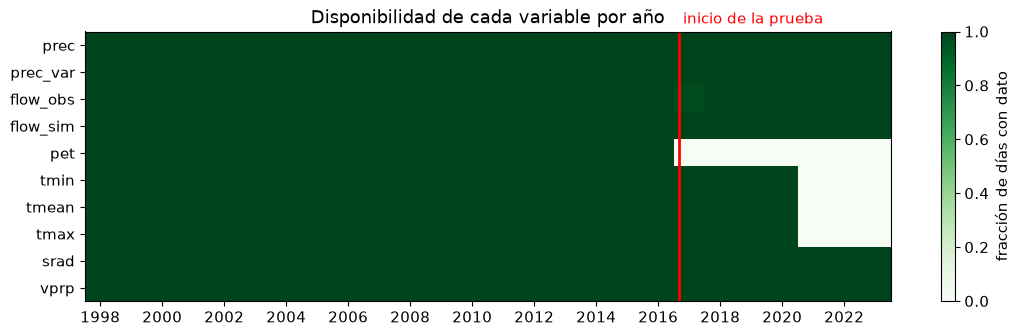

In [ ]:
disponible = d.loc['1998-09-01':'2023-05-31'].notna().groupby(d.loc['1998-09-01':'2023-05-31'].index.year).mean()
fig, ax = plt.subplots(figsize=(13, 3.5))
im = ax.imshow(disponible.T, aspect='auto', cmap='Greens', vmin=0, vmax=1)
ax.set_yticks(range(disponible.shape[1]), disponible.columns)
ax.set_xticks(range(0, len(disponible), 2), disponible.index[::2])
ax.axvline(list(disponible.index).index(2016) + 0.67, color='red', lw=2)
ax.text(list(disponible.index).index(2016) + 0.8, -0.8, 'inicio de la prueba', color='red')
plt.colorbar(im, label='fracción de días con dato')
ax.set_title('Disponibilidad de cada variable por año'); plt.show()

- `pet` termina en 2016 y las temperaturas en 2020: **no sirven** porque faltan en la prueba.
- Variables permitidas en Chosica: `prec` (lluvia PISCOp), `prec_var` (varianza de la lluvia, PISCOp), `srad` (radiación, ERA5-Land), `vprp` (presión de vapor, ERA5-Land) y `flow_sim` (caudal simulado por el modelo hidrológico **PISCO-ARNOVIC**).
- Los forzantes empiezan en **1981**: una ventana de 365 días antes de 1998 no es problema.
- Usar `flow_sim` como **entrada** está permitido: es un modelo **híbrido** (física + *deep learning*) que corrige al modelo hidrológico.

# 2. Estandarización: periodos, métricas y formato de entrega

Esta sección es **igual para todos los equipos y no se modifica**. Define:

- `datos`: los forzantes permitidos de Chosica, de 1981 a 2025.
- `caudal`: el caudal observado **con la prueba oculta** (NaN). Es el único caudal que pueden usar para entrenar.
- `evaluar(pred)`: calcula las métricas oficiales en entrenamiento, validación y, cuando se abra el tablero privado, prueba.
- `guardar_envio(pred, equipo)`: escribe el CSV de entrega en el formato oficial.

Una predicción válida es una **serie de pandas** con el caudal simulado (mm/día) para **cada día** de 1998-09-01 a 2023-05-31, sin huecos ni negativos. Se predicen todos los días aunque no haya observación; las métricas solo usan los días con dato.

In [ ]:
# ===================== CONFIGURACIÓN OFICIAL DEL DESAFÍO (NO MODIFICAR) =====================
PERIODOS = {'entrena': ('1998-09-01', '2012-08-31'),
            'valida':  ('2012-09-01', '2016-08-31'),
            'prueba':  ('2016-09-01', '2023-05-31')}
FECHAS_ENVIO = pd.date_range('1998-09-01', '2023-05-31', freq='D')
PERMITIDAS = ['prec', 'prec_var', 'srad', 'vprp', 'flow_sim']

datos = d[PERMITIDAS].copy()                                   # forzantes 1981–2025
_respuestas = d['flow_obs'].reindex(FECHAS_ENVIO)              # caudal completo (lo usa solo evaluar)
caudal = _respuestas.copy()
caudal[PERIODOS['prueba'][0]:] = np.nan                        # la prueba queda oculta
TABLERO_PRIVADO_ABIERTO = False

def en_periodo(indice, periodo):
    inicio, fin = PERIODOS[periodo]
    return (indice >= inicio) & (indice <= fin)

def metricas(obs, sim):
    ok = ~np.isnan(obs)
    o, s = obs[ok], sim[ok]
    nse = 1 - np.sum((o - s) ** 2) / np.sum((o - o.mean()) ** 2)
    r = np.corrcoef(o, s)[0, 1]
    kge = 1 - np.sqrt((r - 1) ** 2 + (s.std() / o.std() - 1) ** 2 + (s.mean() / o.mean() - 1) ** 2)
    lo, ls = np.log(o), np.log(np.maximum(s, 1e-3))
    nse_log = 1 - np.sum((lo - ls) ** 2) / np.sum((lo - lo.mean()) ** 2)
    pbias = 100 * (s.sum() - o.sum()) / o.sum()
    rmse = np.sqrt(np.mean((o - s) ** 2))
    return {'NSE': nse, 'KGE': kge, 'NSE_log': nse_log, 'PBIAS_%': pbias, 'RMSE': rmse, 'n_dias': int(ok.sum())}

def validar_envio(pred):
    if not isinstance(pred, pd.Series):
        raise TypeError('La predicción debe ser una pd.Series indexada por fecha')
    pred = pred.reindex(FECHAS_ENVIO)
    if pred.isna().any():
        faltan = pred.index[pred.isna()]
        raise ValueError(f'Faltan {len(faltan)} días (p. ej., {faltan[0].date()}). Predice TODOS los días.')
    if (pred < 0).any():
        raise ValueError('Hay caudales negativos')
    return pred.astype(float)

def evaluar(pred, nombre='modelo'):
    pred = validar_envio(pred)
    periodos = ['entrena', 'valida'] + (['prueba'] if TABLERO_PRIVADO_ABIERTO else [])
    filas = {per: metricas(_respuestas[en_periodo(FECHAS_ENVIO, per)].values,
                           pred[en_periodo(FECHAS_ENVIO, per)].values) for per in periodos}
    tabla = pd.DataFrame(filas).T.astype({"n_dias": int})
    tabla.index = pd.MultiIndex.from_product([[nombre], tabla.index], names=['modelo', 'periodo'])
    return tabla.round(3)

def guardar_envio(pred, equipo):
    pred = validar_envio(pred)
    archivo = f'envio_{equipo}.csv'
    pred.rename('flow_pred').rename_axis('date').to_csv(archivo, float_format='%.4f')
    print(f'Envío guardado: {archivo} ({len(pred)} días)')
    return archivo
# ============================================================================================

print({per: int((caudal[en_periodo(FECHAS_ENVIO, per)].notna()).sum()) for per in ['entrena', 'valida']},
      '| días con caudal visibles para entrenar')

{'entrena': 5109, 'valida': 1461} | días con caudal visibles para entrenar


### Las métricas oficiales

| Métrica | Fórmula / idea | Ideal | Qué castiga |
|---|---|---|---|
| **NSE** | $1 - \frac{\sum (Q_o - Q_s)^2}{\sum (Q_o - \bar{Q}_o)^2}$ | 1 | Errores en **crecidas** (errores al cuadrado) |
| **KGE** | Combina correlación, variabilidad y sesgo | 1 | Desbalance entre los tres componentes |
| **NSE_log** | NSE sobre $\log Q$ | 1 | Errores en **estiaje** |
| **PBIAS** | $100 \cdot \frac{\sum Q_s - \sum Q_o}{\sum Q_o}$ | 0 % | Sobre- (+) o subestimación (−) del volumen |

El tablero ordena por **NSE de prueba**. Las otras métricas sirven para **diagnosticar**: un modelo con buen NSE puede tener un PBIAS de −15 % o fallar todo el estiaje.

# 3. Líneas base

Antes de proponer un modelo hay que saber **qué nivel superar**. Un modelo de *deep learning* que no supera a una referencia simple no aporta.

## 3.1 Climatología y PISCO-ARNOVIC

In [ ]:
envios = {}                                    # aquí se guardan TODAS las predicciones para el tablero

# Línea base 1: climatología (caudal medio de cada día del año en el entrenamiento)
entrena_obs = caudal[en_periodo(FECHAS_ENVIO, 'entrena')].dropna()
clim = np.exp(np.log(entrena_obs).groupby(entrena_obs.index.day_of_year).mean())
clim = clim.reindex(range(1, 367)).interpolate(limit_direction='both')
envios['Climatología'] = pd.Series(clim.loc[FECHAS_ENVIO.day_of_year].values, index=FECHAS_ENVIO)

# Línea base 2: el modelo hidrológico PISCO-ARNOVIC
envios['PISCO-ARNOVIC'] = datos['flow_sim'].reindex(FECHAS_ENVIO)

pd.concat([evaluar(p, n) for n, p in envios.items()])

NSE    KGE  NSE_log  PBIAS_%   RMSE  n_dias
modelo        periodo                                               
Climatología  entrena  0.654  0.691    0.702   -3.240  0.395    5109
              valida   0.549  0.635    0.578    4.812  0.459    1461
PISCO-ARNOVIC entrena  0.803  0.878    0.782   -5.679  0.298    5109
              valida   0.801  0.798    0.817    1.076  0.305    1461

La climatología solo conoce el calendario: **no sabe si el año es húmedo o seco**. ARNOVIC es un modelo hidrológico regional calibrado para todo el Perú; sin ajustarlo a esta cuenca ya consigue NSE ≈ 0.8.

## 3.2 LSTM de referencia (Lab 9_3)

La LSTM de referencia es la receta básica del Lab 9_3:

1. **Entradas:** `prec`, `srad`, `vprp` normalizadas con media y desviación **del entrenamiento**.
2. **Ventana:** los 180 días anteriores a cada fecha.
3. **Objetivo:** $\log Q$ normalizado; se entrena solo con los días que tienen dato.
4. **Early stopping** con la validación.

La escribimos como una función con parámetros para que cada equipo la pueda reutilizar y cambiar.

In [ ]:
def preparar_entradas(tabla, transformar_log=('flow_sim',)):
    # Normaliza cada columna con media y desviación del ENTRENAMIENTO; log a las variables sesgadas
    X = tabla.copy()
    for c in X.columns:
        if c in transformar_log:
            X[c] = np.log(X[c].clip(lower=1e-3))
    entrena = en_periodo(X.index, 'entrena')
    X = (X - X[entrena].mean()) / X[entrena].std()
    return X.fillna(0)

def crear_ventanas(X, fechas, ventana):
    # (n_fechas, ventana, n_variables): los `ventana` días que terminan en cada fecha
    posicion = X.index.get_indexer(fechas)
    valores = X.values.astype('float32')
    return np.stack([valores[p - ventana + 1:p + 1] for p in posicion])

# Objetivo: log(Q) normalizado con el entrenamiento
q_log = np.log(caudal)
Q_MEDIA = q_log[en_periodo(FECHAS_ENVIO, 'entrena')].mean()
Q_DESV = q_log[en_periodo(FECHAS_ENVIO, 'entrena')].std()

def a_caudal(v):
    return np.exp(np.asarray(v).ravel() * Q_DESV + Q_MEDIA)

def entrenar_lstm(columnas=('prec', 'srad', 'vprp'), ventana=180, unidades=64, dropout=0.2,
                  semillas=(0,), epocas=60, tasa=1e-3, lote=128, tabla=None):
    # Entrena una LSTM por semilla y devuelve el PROMEDIO (ensamble) de sus predicciones
    X = preparar_entradas((datos if tabla is None else tabla)[list(columnas)])
    X_todo = crear_ventanas(X, FECHAS_ENVIO, ventana)
    y = ((q_log - Q_MEDIA) / Q_DESV).values.astype('float32')
    con_dato = ~np.isnan(y)
    e = en_periodo(FECHAS_ENVIO, 'entrena') & con_dato
    v = en_periodo(FECHAS_ENVIO, 'valida') & con_dato
    predicciones = []
    for semilla in semillas:
        keras.utils.set_random_seed(semilla)
        modelo = keras.Sequential([keras.Input(shape=X_todo.shape[1:]), layers.LSTM(unidades),
                                   layers.Dropout(dropout), layers.Dense(1)])
        modelo.compile(optimizer=keras.optimizers.Adam(tasa), loss='mse')
        modelo.fit(X_todo[e], y[e], epochs=epocas, batch_size=lote, validation_data=(X_todo[v], y[v]),
                   verbose=0, callbacks=[keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True)])
        predicciones.append(a_caudal(modelo.predict(X_todo, verbose=0, batch_size=1024)))
    return pd.Series(np.mean(predicciones, axis=0), index=FECHAS_ENVIO)

t0 = time.time()
envios['LSTM referencia'] = entrenar_lstm()
print(f'{time.time() - t0:.0f} s')
pd.concat([evaluar(p, n) for n, p in envios.items()])

39 s


NSE    KGE  NSE_log  PBIAS_%   RMSE  n_dias
modelo          periodo                                               
Climatología    entrena  0.654  0.691    0.702   -3.240  0.395    5109
                valida   0.549  0.635    0.578    4.812  0.459    1461
PISCO-ARNOVIC   entrena  0.803  0.878    0.782   -5.679  0.298    5109
                valida   0.801  0.798    0.817    1.076  0.305    1461
LSTM referencia entrena  0.895  0.856    0.886   -5.085  0.217    5109
                valida   0.809  0.791    0.824   -0.775  0.299    1461

Este es el nivel a superar. Recuerda que la tabla todavía **no muestra la prueba**: hay que decidir con la validación.

# 4. Tu modelo

Cada equipo tiene ~55 minutos para mejorar la referencia. Algunas ideas, ordenadas por lab:

| Lab | Idea | Pista |
|---|---|---|
| 9_1 | **MLP** con variables construidas a mano | Lluvia acumulada de 3, 7, 30, 90 y 180 días; mes del año (seno y coseno) |
| 9_2 | **CNN 1D** sobre la ventana | `Conv1D` + `GlobalAveragePooling1D`: detecta patrones locales en la ventana de lluvia |
| 9_3 | **LSTM** con otras entradas o hiperparámetros | `prec_var`, `flow_sim`, ventana de 365 días, más unidades, 2 capas, más semillas |
| 9_4 | **Transformer** (encoder) | Atención sobre la ventana; con pocos datos, cuidado con el sobreajuste |
| 9_5 | **Grafo + LSTM** con las subcuencas aguas arriba | Río Blanco, Santa Eulalia y Autisha como nodos |
| — | **Ensamble** | Promediar modelos distintos suele mejorar más que afinar uno solo |

Reglas de trabajo:

- Cada idea nueva se guarda en `envios['nombre']` y se compara en el **tablero público**.
- Anota qué probaste aunque **no** funcione: un experimento fallido también es un resultado.
- Con GPU cada LSTM tarda menos de un minuto; con CPU, unos 2–3 minutos.

## 4.1 Ejemplo: cambiar las entradas de la LSTM

La función `entrenar_lstm` acepta otras columnas, otra ventana y varias semillas. Un ejemplo con todas las variables de Chosica:

In [ ]:
envios['LSTM todas las variables'] = entrenar_lstm(columnas=PERMITIDAS)
pd.concat([evaluar(p, n) for n, p in envios.items()])

NSE    KGE  NSE_log  PBIAS_%   RMSE  \
modelo                   periodo                                          
Climatología             entrena  0.654  0.691    0.702   -3.240  0.395   
                         valida   0.549  0.635    0.578    4.812  0.459   
PISCO-ARNOVIC            entrena  0.803  0.878    0.782   -5.679  0.298   
                         valida   0.801  0.798    0.817    1.076  0.305   
LSTM referencia          entrena  0.895  0.856    0.886   -5.085  0.217   
                         valida   0.809  0.791    0.824   -0.775  0.299   
LSTM todas las variables entrena  0.936  0.937    0.924   -1.888  0.169   
                         valida   0.831  0.857    0.821    3.954  0.281   

                                  n_dias  
modelo                   periodo          
Climatología             entrena    5109  
                         valida     1461  
PISCO-ARNOVIC            entrena    5109  
                         valida     1461  
LSTM referencia          entrena    5109  
                         valida     1461  
LSTM todas las variables entrena    5109  
                         valida     1461

## 4.2 Variables construidas a mano (para un MLP o como entradas extra)

En el Lab 9_1 el MLP no tenía memoria. Aquí podemos **darle memoria construyendo variables**: la lluvia acumulada de los días anteriores resume el estado de humedad de la cuenca. Estas variables también se pueden agregar a la LSTM con el argumento `tabla`.

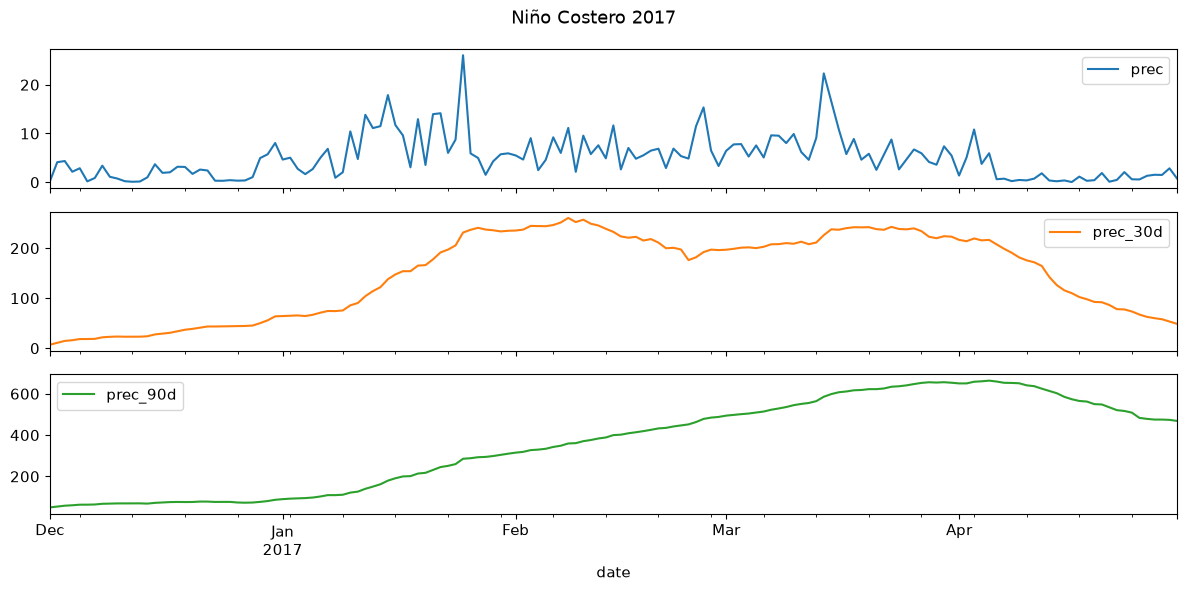

In [ ]:
variables = pd.DataFrame(index=datos.index)
for dias in [3, 7, 30, 90, 180]:
    variables[f'prec_{dias}d'] = datos['prec'].rolling(dias, min_periods=1).sum()
variables['mes_sin'] = np.sin(2 * np.pi * datos.index.day_of_year / 365.25)
variables['mes_cos'] = np.cos(2 * np.pi * datos.index.day_of_year / 365.25)
variables = pd.concat([datos, variables], axis=1)
variables.loc['2016-12-01':'2017-04-30', ['prec', 'prec_30d', 'prec_90d']].plot(subplots=True, figsize=(12, 6),
                                                                              title='Niño Costero 2017')
plt.tight_layout(); plt.show()

In [ ]:
# Ejemplo de MLP (Lab 9_1): una fila por día, sin ventana
def entrenar_mlp(columnas, capas=(64, 32), semillas=(0,), epocas=200):
    X = preparar_entradas(variables[list(columnas)]).reindex(FECHAS_ENVIO).values.astype('float32')
    y = ((q_log - Q_MEDIA) / Q_DESV).values.astype('float32')
    con_dato = ~np.isnan(y)
    e = en_periodo(FECHAS_ENVIO, 'entrena') & con_dato
    v = en_periodo(FECHAS_ENVIO, 'valida') & con_dato
    predicciones = []
    for semilla in semillas:
        keras.utils.set_random_seed(semilla)
        modelo = keras.Sequential([keras.Input(shape=(X.shape[1],))] +
                                  [layers.Dense(n, activation='relu') for n in capas] + [layers.Dense(1)])
        modelo.compile(optimizer='adam', loss='mse')
        modelo.fit(X[e], y[e], epochs=epocas, batch_size=128, validation_data=(X[v], y[v]), verbose=0,
                   callbacks=[keras.callbacks.EarlyStopping(patience=15, restore_best_weights=True)])
        predicciones.append(a_caudal(modelo.predict(X, verbose=0)))
    return pd.Series(np.mean(predicciones, axis=0), index=FECHAS_ENVIO)

envios['MLP lluvia acumulada'] = entrenar_mlp(['prec', 'prec_3d', 'prec_7d', 'prec_30d', 'prec_90d', 'prec_180d',
                                              'srad', 'vprp', 'mes_sin', 'mes_cos'])
pd.concat([evaluar(p, n) for n, p in envios.items()])

NSE    KGE  NSE_log  PBIAS_%   RMSE  \
modelo                   periodo                                          
Climatología             entrena  0.654  0.691    0.702   -3.240  0.395   
                         valida   0.549  0.635    0.578    4.812  0.459   
PISCO-ARNOVIC            entrena  0.803  0.878    0.782   -5.679  0.298   
                         valida   0.801  0.798    0.817    1.076  0.305   
LSTM referencia          entrena  0.895  0.856    0.886   -5.085  0.217   
                         valida   0.809  0.791    0.824   -0.775  0.299   
LSTM todas las variables entrena  0.936  0.937    0.924   -1.888  0.169   
                         valida   0.831  0.857    0.821    3.954  0.281   
MLP lluvia acumulada     entrena  0.882  0.927    0.870   -0.910  0.231   
                         valida   0.811  0.861    0.812    5.284  0.298   

                                  n_dias  
modelo                   periodo          
Climatología             entrena    5109  
                         valida     1461  
PISCO-ARNOVIC            entrena    5109  
                         valida     1461  
LSTM referencia          entrena    5109  
                         valida     1461  
LSTM todas las variables entrena    5109  
                         valida     1461  
MLP lluvia acumulada     entrena    5109  
                         valida     1461

## 4.3 Datos de las estaciones aguas arriba (opcional, para el Lab 9_5)

Si cargaste los archivos opcionales, aquí quedan los forzantes de cada subcuenca y el caudal observado de **Río Blanco**. Río Blanco no es Chosica: su caudal **sí** se permite como entrada, porque es otra estación que en la realidad también se mide. Tiene algunos huecos que hay que rellenar antes de usarlo.

Para armar el grafo, recuerda el Lab 9_5: `downstream_gauge_id` da las aristas y conviene usar el forzante **incremental** de cada subcuenca.

In [ ]:
aguas_arriba = {g: pd.read_csv(f'{g}.csv', parse_dates=['date'], index_col='date')
                for g in ['PE_212604', 'PE_472E24B0', 'PE_47A03AC4'] if os.path.exists(f'{g}.csv')}
for g, tabla in aguas_arriba.items():
    print(f"{g} {atributos.loc[g, 'gauge_name']:<14s} drena a {atributos.loc[g, 'downstream_gauge_id']}"
          f"  área {atributos.loc[g, 'area']:6.0f} km²")

if 'PE_212604' in aguas_arriba:
    rio_blanco = aguas_arriba['PE_212604']['flow_obs']
    print('Río Blanco: días sin caudal entre 1998 y 2023 =', int(rio_blanco.loc['1998-09':'2023-05'].isna().sum()))

PE_212604 Rio Blanco     drena a PE_202906  área    202 km²
PE_472E24B0 Santa Eulalia  drena a PE_202906  área   1077 km²
PE_47A03AC4 Autisha        drena a PE_472E24B0  área    792 km²
Río Blanco: días sin caudal entre 1998 y 2023 = 707


## 4.4 Tu propuesta

Usa esta celda (y las que necesites) para tu modelo. Al final, la predicción debe quedar en `envios['nombre de tu modelo']`. Puedes copiar `entrenar_lstm` o `entrenar_mlp` y cambiar la arquitectura: por ejemplo, reemplazar `layers.LSTM(unidades)` por una CNN 1D o un bloque Transformer.

In [ ]:
# Tu modelo aquí. Ejemplos de llamadas:
# envios['LSTM 365 días'] = entrenar_lstm(columnas=['prec', 'srad', 'vprp'], ventana=365)
# envios['LSTM 3 semillas'] = entrenar_lstm(semillas=(0, 1, 2))
# envios['LSTM + acumulados'] = entrenar_lstm(columnas=['prec', 'prec_30d', 'srad', 'vprp'], tabla=variables)
# envios['Ensamble'] = (envios['LSTM referencia'] + envios['MLP lluvia acumulada']) / 2

# 5. Tableros

## 5.1 Tablero público (validación)

Ordena todos los modelos por **NSE de validación**. Es la única tabla con la que se elige el modelo final.

In [ ]:
def tablero(periodo):
    tabla = pd.concat([evaluar(p, n) for n, p in envios.items()]).xs(periodo, level='periodo')
    return tabla.sort_values(['NSE', 'KGE'], ascending=False).drop(columns='n_dias')

tablero('valida').style.background_gradient(subset=['NSE', 'KGE', 'NSE_log'], cmap='Greens').format('{:.3f}')

,NSE,KGE,NSE_log,PBIAS_%,RMSE
modelo,,,,,
LSTM todas las variables,0.831,0.857,0.821,3.954,0.281
MLP lluvia acumulada,0.811,0.861,0.812,5.284,0.298
LSTM referencia,0.809,0.791,0.824,-0.775,0.299
PISCO-ARNOVIC,0.801,0.798,0.817,1.076,0.305
Climatología,0.549,0.635,0.578,4.812,0.459


Antes de abrir el tablero privado, **cada equipo elige un solo modelo** según la tabla anterior y lo guarda con el formato oficial:

In [ ]:
EQUIPO = 'equipo_1'                               # sin espacios ni tildes
ELEGIDO = tablero('valida').index[0]              # o el nombre de tu modelo, p. ej. 'LSTM 3 semillas'
print('Modelo elegido:', ELEGIDO)
archivo = guardar_envio(envios[ELEGIDO], EQUIPO)
pd.read_csv(archivo).head()

Modelo elegido: LSTM todas las variables
Envío guardado: envio_equipo_1.csv (9039 días)


,date,flow_pred
0,1998-09-01,0.8261
1,1998-09-02,0.8264
2,1998-09-03,0.8237
3,1998-09-04,0.8269
4,1998-09-05,0.8308


## 5.2 Tablero privado (prueba)

⚠️ **Ejecuta esta celda una sola vez**, después de guardar tu envío. A partir de aquí ya no se ajustan modelos: solo se analizan.

In [ ]:
TABLERO_PRIVADO_ABIERTO = True
privado = tablero('prueba')
privado['NSE valida'] = tablero('valida')['NSE']
privado['caída NSE'] = privado['NSE valida'] - privado['NSE']
privado.style.background_gradient(subset=['NSE', 'KGE', 'NSE_log'], cmap='Greens').format('{:.3f}')

,NSE,KGE,NSE_log,PBIAS_%,RMSE,NSE valida,caída NSE
modelo,,,,,,,
LSTM todas las variables,0.741,0.837,0.761,11.104,0.300,0.831,0.090
LSTM referencia,0.696,0.836,0.730,9.206,0.325,0.809,0.113
PISCO-ARNOVIC,0.601,0.703,0.726,13.179,0.372,0.801,0.200
Climatología,0.470,0.681,0.504,12.879,0.429,0.549,0.079
MLP lluvia acumulada,0.317,0.509,0.688,18.611,0.487,0.811,0.494


Compara las dos columnas de NSE. Es normal que la prueba sea **más difícil** que la validación: incluye el Niño Costero de 2017 y años que el modelo nunca vio. Lo importante es si **el orden** entre modelos se mantiene. Si el mejor en validación cae mucho en la prueba, probablemente se sobreajustó a la validación o depende de algo que cambió en la prueba.

En la ejecución guardada de este notebook pasó justamente eso: el **MLP de lluvia acumulada** quedó 2.º en validación (NSE 0.81) y cayó a ~0.3 en la prueba, mientras que las LSTM mantuvieron su lugar. Un buen puntaje en un solo periodo de validación **no garantiza** un buen puntaje fuera de él. Por eso conviene preferir modelos que funcionan bien de forma **consistente** (varias semillas, varias métricas) y no el que ganó por poco.

## 5.3 ¿Dónde falla el modelo?

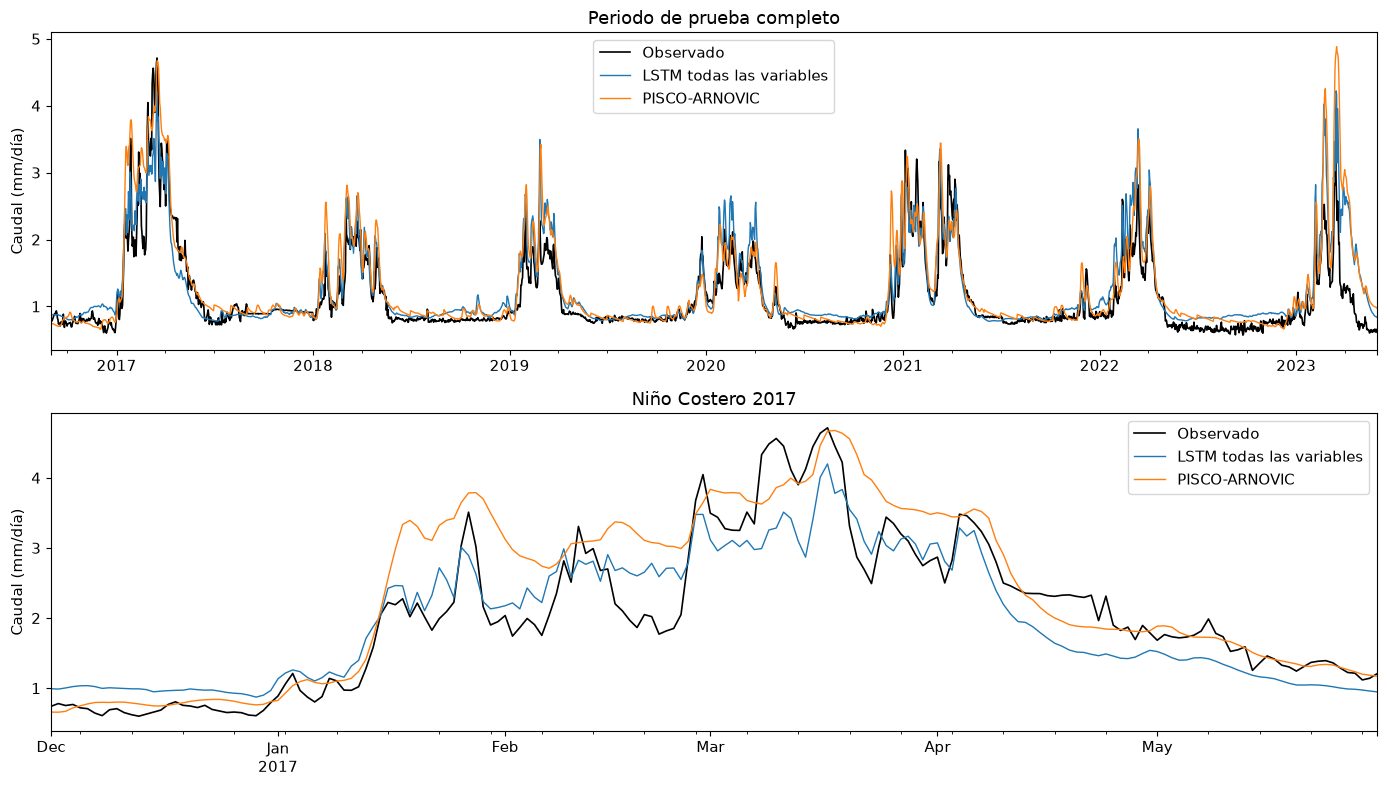

In [ ]:
mostrar = [ELEGIDO, 'PISCO-ARNOVIC']
fig, axes = plt.subplots(2, 1, figsize=(14, 8))
for ax, (inicio, fin, titulo) in zip(axes, [('2016-09-01', '2023-05-31', 'Periodo de prueba completo'),
                                            ('2016-12-01', '2017-05-31', 'Niño Costero 2017')]):
    _respuestas.loc[inicio:fin].plot(ax=ax, color='k', lw=1.2, label='Observado')
    for nombre in mostrar:
        envios[nombre].loc[inicio:fin].plot(ax=ax, lw=1, label=nombre)
    ax.set_title(titulo); ax.set_ylabel('Caudal (mm/día)'); ax.set_xlabel(''); ax.legend()
plt.tight_layout(); plt.show()

In [ ]:
# Error por año hidrológico (septiembre–agosto) en la prueba
prueba = en_periodo(FECHAS_ENVIO, 'prueba')
anio = (FECHAS_ENVIO[prueba] - pd.DateOffset(months=8)).year
filas = {}
for nombre in mostrar:
    for a in sorted(set(anio)):
        sel = anio == a
        filas[(nombre, f'{a}-{a + 1}')] = metricas(_respuestas[prueba].values[sel], envios[nombre][prueba].values[sel])
pd.DataFrame(filas).T[['NSE', 'NSE_log', 'PBIAS_%', 'n_dias']].unstack(0).round(2)

NSE                                NSE_log  \
          LSTM todas las variables PISCO-ARNOVIC LSTM todas las variables   
2016-2017                     0.89          0.81                     0.88   
2017-2018                     0.78          0.49                     0.83   
2018-2019                     0.53          0.39                     0.67   
2019-2020                     0.62          0.77                     0.76   
2020-2021                     0.92          0.79                     0.94   
2021-2022                     0.59          0.67                     0.69   
2022-2023                    -0.23         -1.13                     0.11   

                                         PBIAS_%                \
          PISCO-ARNOVIC LSTM todas las variables PISCO-ARNOVIC   
2016-2017          0.88                    -0.83         11.04   
2017-2018          0.66                     6.58         13.15   
2018-2019          0.66                    16.45         15.00   
2019-2020          0.82                    11.68          3.58   
2020-2021          0.85                    -0.32          4.06   
2021-2022          0.73                    19.32         13.45   
2022-2023         -0.03                    40.45         43.25   

                            n_dias                
          LSTM todas las variables PISCO-ARNOVIC  
2016-2017                    365.0         365.0  
2017-2018                    356.0         356.0  
2018-2019                    365.0         365.0  
2019-2020                    366.0         366.0  
2020-2021                    365.0         365.0  
2021-2022                    365.0         365.0  
2022-2023                    273.0         273.0

# 6. Puesta en común

Cada equipo responde en 2–3 minutos:

1. ¿Qué modelo eligieron y por qué? ¿Superó a ARNOVIC y a la LSTM de referencia en la **validación**? ¿Y en la **prueba**?
2. ¿Cuánto cayó el NSE de validación a prueba? ¿Su modelo ganó o perdió posiciones al abrir el tablero privado?
3. ¿Qué año o evento simula peor? ¿Es un problema de crecidas (NSE) o de estiaje (NSE_log)?
4. ¿Qué probaron que **no** funcionó?
5. En la prueba casi todos los modelos tienen PBIAS positivo (sobrestiman el volumen). En esta cuenca hay embalses y trasvases que no están en los datos. ¿Qué parte del error creen que viene de eso y cómo lo comprobarían?

## Lista de verificación de un buen modelamiento

- [ ] Periodos cronológicos: nunca mezclar días al azar entre entrenamiento y prueba (la autocorrelación filtra información).
- [ ] Normalización con estadísticas **solo del entrenamiento**.
- [ ] *Early stopping* y elección de hiperparámetros con la **validación**, nunca con la prueba.
- [ ] Solo variables que existen en **todo** el periodo a predecir.
- [ ] Varias semillas antes de concluir que un modelo es mejor que otro.
- [ ] Una predicción para **cada día** y en las **unidades** pedidas (mm/día).
- [ ] Comparar siempre contra líneas base simples.
- [ ] Mirar el hidrograma y no solo el NSE.

## Lecturas recomendadas

- Kratzert, F., et al. (2018). Rainfall–runoff modelling using Long Short-Term Memory (LSTM) networks. *HESS*, 22, 6005–6022.
- Gupta, H. V., Kling, H., Yilmaz, K. K., & Martinez, G. F. (2009). Decomposition of the mean squared error and NSE performance criteria. *Journal of Hydrology*, 377, 80–91.
- Klemeš, V. (1986). Operational testing of hydrological simulation models. *Hydrological Sciences Journal*, 31(1), 13–24.
- Kaggle: [competiciones](https://www.kaggle.com/competitions) — busca competencias de series de tiempo para ver cómo se organizan los tableros público y privado.